运行约定：以本 Notebook 所在目录作为工作目录，从第一单元顺序运行。首个代码单元仅建立数据与输出目录。历史输出保留，不代表当前环境已验证。


In [ ]:
from pathlib import Path
Path('../data').mkdir(parents=True, exist_ok=True)
Path('../outputs').mkdir(parents=True, exist_ok=True)


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import time
from matplotlib import pyplot as plt

# 使用LeNet-5网络结构创建CIFAR-10分类器

CIFAR-10 是由 Hinton 的学生 Alex Krizhevsky 和 Ilya Sutskever 整理的一个用于识别普适物体的小型数据集。一共包含 10 个类别的 RGB 彩色图 片：飞机（ airlane ）、汽车（ automobile ）、鸟类（ bird ）、猫（ cat ）、鹿（ deer ）、狗（ dog ）、蛙类（ frog ）、马（ horse ）、船（ ship ）和卡车（ truck ）。图片的尺寸为 32×32 ，数据集中一共有 50000 张训练圄片和 10000 张测试图片。 

CIFAR-10 的图片样例如图所示。

![](../assets/lenet/cifar-10.png)

## 2.1 下载并加载数据，并做出一定的预先处理

In [3]:
# 在线下载慢，可以选择直接拷贝

!cp -r /workspace/DataSet/cvdata/CIFAR10/ ../data/

In [4]:
pipline_train = transforms.Compose([
    #随机旋转图片
    transforms.RandomHorizontalFlip(),
    #将图片尺寸resize到32x32
    transforms.Resize((32,32)),
    #将图片转化为Tensor格式
    transforms.ToTensor(),
    #正则化(当模型出现过拟合的情况时，用来降低模型的复杂度)
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])
pipline_test = transforms.Compose([
    #将图片尺寸resize到32x32
    transforms.Resize((32,32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])
#下载数据集
train_set = datasets.CIFAR10(root="../data/CIFAR10", train=True, download=True, transform=pipline_train)
test_set = datasets.CIFAR10(root="../data/CIFAR10", train=False, download=True, transform=pipline_test)
#加载数据集
trainloader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(test_set, batch_size=32, shuffle=False)
# 类别信息也是需要我们给定的
classes = ('plane', 'car', 'bird', 'cat','deer', 'dog', 'frog', 'horse', 'ship', 'truck')

## 2.2 搭建LeNet-5神经网络结构，并定义前向传播的过程

LeNet-5网络上文已经搭建过了，由于CIFAR10数据集图像是RGB三通道的，因此LeNet-5网络C1层卷积选择的滤波器需要3通道，网络其它结构跟上文都是一样的。

In [5]:
class LeNetRGB(nn.Module):
    def __init__(self):
        super(LeNetRGB, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)   # 3表示输入是3通道
        self.relu = nn.ReLU()
        self.maxpool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.maxpool2 = nn.MaxPool2d(2, 2)
 
        self.fc1 = nn.Linear(16*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
 
    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = x.view(-1, 16*5*5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        output = F.log_softmax(x, dim=1)
        return output

## 2.3 将定义好的网络结构搭载到GPU/CPU，并定义优化器

使用SGD（随机梯度下降）优化，学习率为0.001，动量为0.9

In [6]:
#创建模型，部署gpu
device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

print(f"Using device: {device}")
model = LeNetRGB().to(device)
#定义优化器
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
#optimizer = optim.Adam(model.parameters(), lr=0.001)

训练和测试函数的定义跟LeNet-5章节定义的一样。

## 2.4 定义训练过程

In [7]:
def train_runner(model, device, trainloader, optimizer, epoch):
    #训练模型, 启用 BatchNormalization 和 Dropout, 将BatchNormalization和Dropout置为True
    model.train()
    total = 0
    correct =0.0
    
    #enumerate迭代已加载的数据集,同时获取数据和数据下标
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        #把模型部署到device上
        inputs, labels = inputs.to(device), labels.to(device)
        #初始化梯度
        optimizer.zero_grad()
        #保存训练结果
        outputs = model(inputs)
        #计算损失和
        #多分类情况通常使用cross_entropy(交叉熵损失函数), 而对于二分类问题, 通常使用sigmod
        loss = F.cross_entropy(outputs, labels)
        #获取最大概率的预测结果
        #dim=1表示返回每一行的最大值对应的列下标
        predict = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predict == labels).sum().item()
        #反向传播
        loss.backward()
        #更新参数
        optimizer.step()
        if i % 100 == 0:   # 每100个batch打印一次
            #loss.item()表示当前loss的数值
            print("Train Epoch{} \t Loss: {:.6f}, accuracy: {:.6f}%".format(epoch, loss.item(), 100*(correct/total)))
            Loss.append(loss.item())
            Accuracy.append(correct/total)
    return loss.item(), correct/total

## 2.5 定义测试过程

In [8]:
def test_runner(model, device, testloader):
    #模型验证, 必须要写, 否则只要有输入数据, 即使不训练, 它也会改变权值
    #因为调用eval()将不启用 BatchNormalization 和 Dropout, BatchNormalization和Dropout置为False
    model.eval()
    #统计模型正确率, 设置初始值
    correct = 0.0
    test_loss = 0.0
    total = 0
    #torch.no_grad将不会计算梯度, 也不会进行反向传播
    with torch.no_grad():
        for data, label in testloader:
            data, label = data.to(device), label.to(device)
            output = model(data)
            test_loss += F.cross_entropy(output, label).item()
            predict = output.argmax(dim=1)
            #计算正确数量
            total += label.size(0)
            correct += (predict == label).sum().item()
        #计算损失值
        print("test_avarage_loss: {:.6f}, accuracy: {:.6f}%".format(test_loss/total, 100*(correct/total)))

## 2.6 运行

start_time 2026-01-09 15:58:21
Train Epoch1 	 Loss: 2.308652, accuracy: 17.187500%
Train Epoch1 	 Loss: 2.226627, accuracy: 12.964109%
Train Epoch1 	 Loss: 1.879748, accuracy: 17.638371%
Train Epoch1 	 Loss: 1.758440, accuracy: 21.620640%
Train Epoch1 	 Loss: 1.627312, accuracy: 24.809071%
Train Epoch1 	 Loss: 1.614480, accuracy: 27.732036%
Train Epoch1 	 Loss: 1.507064, accuracy: 30.017679%
Train Epoch1 	 Loss: 1.616337, accuracy: 31.969954%
test_avarage_loss: 0.046879, accuracy: 45.030000%
end_time:  2026-01-09 15:58:36 

start_time 2026-01-09 15:58:36
Train Epoch2 	 Loss: 1.653931, accuracy: 45.312500%
Train Epoch2 	 Loss: 1.387306, accuracy: 47.308168%
Train Epoch2 	 Loss: 1.151728, accuracy: 48.095460%
Train Epoch2 	 Loss: 1.565645, accuracy: 48.567276%
Train Epoch2 	 Loss: 1.362285, accuracy: 49.197319%
Train Epoch2 	 Loss: 1.269166, accuracy: 49.722430%
Train Epoch2 	 Loss: 1.509996, accuracy: 50.335379%
Train Epoch2 	 Loss: 1.289039, accuracy: 50.784593%
test_avarage_loss: 0.04

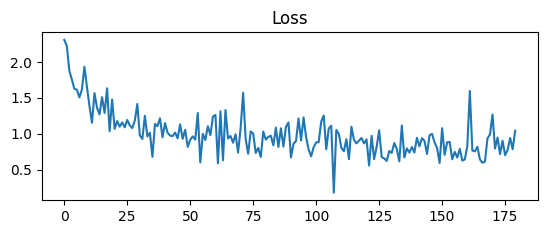

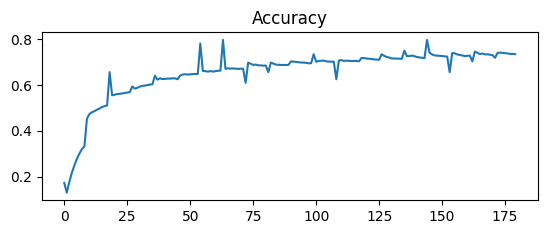

In [9]:
#调用
epoch = 3
Loss = []
Accuracy = []
for epoch in range(1, epoch+1):
    print("start_time",time.strftime('%Y-%m-%d %H:%M:%S',time.localtime(time.time())))
    loss, acc = train_runner(model, device, trainloader, optimizer, epoch)
    Loss.append(loss)
    Accuracy.append(acc)
    test_runner(model, device, testloader)
    print("end_time: ",time.strftime('%Y-%m-%d %H:%M:%S',time.localtime(time.time())),'\n')

print('Finished Training')
plt.subplot(2,1,1)
plt.plot(Loss)
plt.title('Loss')
plt.show()
plt.subplot(2,1,2)
plt.plot(Accuracy)
plt.title('Accuracy')
plt.show()

## 2.7 保存模型

In [10]:
print(model)
torch.save(model, '../outputs/model-lenet-cifar10.pth') #保存模型

LeNetRGB(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (relu): ReLU()
  (maxpool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (maxpool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


## 2.8 模型测试

利用刚刚训练的模型进行CIFAR10类型图片的测试。

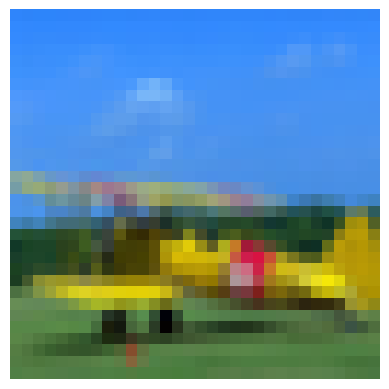

概率： tensor([[3.3309e-01, 3.1562e-02, 2.8280e-03, 4.7721e-07, 6.1530e-01, 4.2408e-07,
         1.9204e-08, 4.1217e-04, 1.6278e-02, 5.3037e-04]], device='cuda:0',
       grad_fn=<SoftmaxBackward0>)
预测类别： 鹿


In [12]:
from PIL import Image
import numpy as np

if __name__ == '__main__':
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    model = torch.load('../outputs/model-lenet-cifar10.pth', weights_only=False) #加载模型
    model = model.to(device)
    model.eval()    #把模型转为test模式
    
    #读取要预测的图片
    # 读取要预测的图片
    img = Image.open("../assets/lenet/test_cifar10.png").convert('RGB') # 读取图像
    #img.show()
    plt.imshow(img) # 显示图片
    plt.axis('off') # 不显示坐标轴
    plt.show()
    
    # 导入图片，图片扩展后为[1，1，32，32]
    trans = transforms.Compose(
        [
            #将图片尺寸resize到32x32
            transforms.Resize((32,32)),
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])
    img = trans(img)
    img = img.to(device)
    img = img.unsqueeze(0)  #图片扩展多一维,因为输入到保存的模型中是4维的[batch_size,通道,长，宽]，而普通图片只有三维，[通道,长，宽]
    
    # 预测 
    # classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
    classes = ('飞机', '汽车', '鸟', '猫', '鹿', '狗', '青蛙', '马', '船', '卡车')
    output = model(img)
    prob = F.softmax(output,dim=1) #prob是10个分类的概率
    print("概率：",prob)
    # print(predict.item())
    value, predicted = torch.max(output.data, 1)
    predict = output.argmax(dim=1)
    pred_class = classes[predicted.item()]
    print("预测类别：",pred_class)